In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/ayushish12/positionsalaries-data/position-salaries data.csv


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/kaggle/input/datasets/ayushish12/positionsalaries-data/position-salaries data.csv')

df.head()

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


In [4]:
X = df['Level'].values.reshape(-1, 1)
y = df['Salary'].values.reshape(-1, 1)

print(X.shape)
print(y.shape)

(10, 1)
(10, 1)


In [5]:
# Normalize X
X_mean = np.mean(X)
X_std = np.std(X)

X_scaled = (X - X_mean) / X_std

# Polynomial features
X_poly = np.hstack((
    np.ones((len(X), 1)),
    X_scaled,
    X_scaled**2,
    X_scaled**3,
    X_scaled**4
))

# Scale Y
y_scaled = y / 100000

print(X_poly)

[[ 1.00000000e+00 -1.56669890e+00  2.45454545e+00 -3.84553367e+00
   6.02479339e+00]
 [ 1.00000000e+00 -1.21854359e+00  1.48484848e+00 -1.80935261e+00
   2.20477502e+00]
 [ 1.00000000e+00 -8.70388280e-01  7.57575758e-01 -6.59385060e-01
   5.73921028e-01]
 [ 1.00000000e+00 -5.22232968e-01  2.72727273e-01 -1.42427173e-01
   7.43801653e-02]
 [ 1.00000000e+00 -1.74077656e-01  3.03030303e-02 -5.27508048e-03
   9.18273646e-04]
 [ 1.00000000e+00  1.74077656e-01  3.03030303e-02  5.27508048e-03
   9.18273646e-04]
 [ 1.00000000e+00  5.22232968e-01  2.72727273e-01  1.42427173e-01
   7.43801653e-02]
 [ 1.00000000e+00  8.70388280e-01  7.57575758e-01  6.59385060e-01
   5.73921028e-01]
 [ 1.00000000e+00  1.21854359e+00  1.48484848e+00  1.80935261e+00
   2.20477502e+00]
 [ 1.00000000e+00  1.56669890e+00  2.45454545e+00  3.84553367e+00
   6.02479339e+00]]


In [6]:
n = len(X)
m_features = X_poly.shape[1]

weights = np.zeros((m_features, 1))

learning_rate = 0.01
epochs = 10000

beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

m = np.zeros_like(weights)
v = np.zeros_like(weights)

loss_history = []

In [7]:
for t in range(1, epochs + 1):

    # Prediction
    y_pred = X_poly @ weights

    # Error
    error = y_pred - y_scaled

    # Gradient
    dw = (2 / n) * (X_poly.T @ error)

    # First moment (Momentum)
    m = beta1 * m + (1 - beta1) * dw

    # Second moment
    v = beta2 * v + (1 - beta2) * (dw ** 2)

    # Bias correction
    m_hat = m / (1 - beta1 ** t)
    v_hat = v / (1 - beta2 ** t)

    # Update weights
    weights -= learning_rate * m_hat / (np.sqrt(v_hat) + epsilon)

    # Loss
    loss = np.mean(error ** 2)
    loss_history.append(loss)

print("Final Loss:", loss_history[-1])
print("Weights:")
print(weights)

Final Loss: 0.021034382284382223
Weights:
[[1.32148437]
 [0.58939514]
 [0.09765625]
 [0.97629947]
 [0.60585937]]


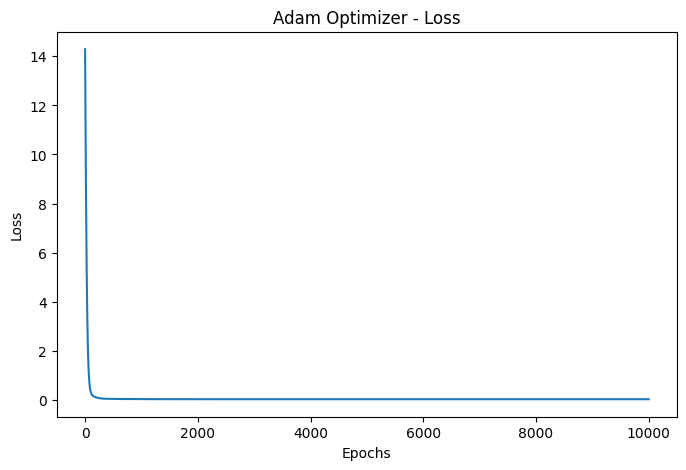

In [8]:
plt.figure(figsize=(8,5))

plt.plot(loss_history)

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Adam Optimizer - Loss')

plt.show()

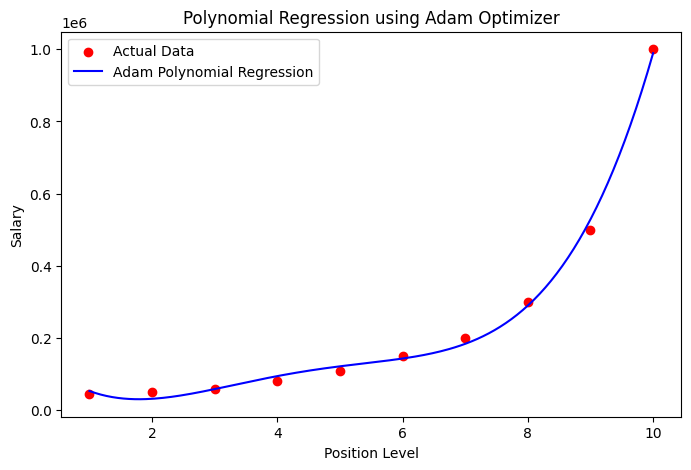

In [9]:
# Generate smooth X values
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

# Normalize
X_curve_scaled = (X_curve - X_mean) / X_std

# Polynomial features
X_curve_poly = np.hstack((
    np.ones((len(X_curve), 1)),
    X_curve_scaled,
    X_curve_scaled**2,
    X_curve_scaled**3,
    X_curve_scaled**4
))

# Predict
y_curve = (X_curve_poly @ weights) * 100000

# Plot
plt.figure(figsize=(8,5))

plt.scatter(X, y, color='red', label='Actual Data')

plt.plot(X_curve, y_curve, color='blue', label='Adam Polynomial Regression')

plt.xlabel('Position Level')
plt.ylabel('Salary')
plt.title('Polynomial Regression using Adam Optimizer')

plt.legend()
plt.show()